# NumCompute-Stream demo: learning from a stream of chunks

This notebook trains a decision tree on data that arrives **chunk by chunk**, as in a
stream. It shows the four steps of the assignment:

1. load a CSV file with the package's own `io.load_csv`,
2. split the data into chunks to simulate a stream,
3. train a pipeline incrementally with `partial_fit()` on each chunk,
4. log and visualise the metrics over time with `visualise.py`.

**Dataset.** *Banknote Authentication* (V. Lohweg, UCI Machine Learning Repository,
CC BY 4.0, <https://archive.ics.uci.edu/dataset/267/banknote+authentication>).
It has 1372 banknote images, each described by 4 numeric features of its wavelet
transform (variance, skewness, kurtosis, entropy) and a binary class (0 or 1) that
says whether the note is genuine or forged. A header row was added to the original
file, which is otherwise unchanged.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Use the package of this repository, even if it is not installed.
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np

from numcompute_stream.io import load_csv
from numcompute_stream.metrics import StreamingF1
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import SimpleImputer, StandardScaler
from numcompute_stream.stats import StreamingStats
from numcompute_stream.stream import StreamTrainer, iter_chunks
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.visualise import (compare_models, plot_metric_over_time,
                                         plot_predictions_vs_ground_truth)

SEED = 0          # makes the shuffling and the tree reproducible
CHUNK_SIZE = 50   # samples per chunk of the stream
BUFFER_SIZE = 200 # samples the tree collects before each retrain

## 2. Load the CSV file with `io.load_csv`

The first row holds the column names, so it is skipped. The last column is the label.

In [2]:
data = load_csv("banknote.csv", delimiter=",", skiprows=1)
X, y = data[:, :-1], data[:, -1].astype(int)

print(f"{X.shape[0]} samples, {X.shape[1]} features, "
      f"{int(np.isnan(data).sum())} missing values")
classes, counts = np.unique(y, return_counts=True)
print("Samples per class:", {int(c): int(n) for c, n in zip(classes, counts)})
print("First labels of the file:", y[:8], " last labels:", y[-8:])

1372 samples, 4 features, 0 missing values
Samples per class: {0: 762, 1: 610}
First labels of the file: [0 0 0 0 0 0 0 0]  last labels: [1 1 1 1 1 1 1 1]


The file is **sorted by class**: all the class 0 notes come first. Streamed in this
order, the model would only see one class for the first half of the stream. The rows
are therefore shuffled once, with a fixed seed, to simulate the order in which notes
would arrive at a bank.

In [3]:
order = np.random.default_rng(SEED).permutation(len(y))
X, y = X[order], y[order]

## 3. Split the data into chunks

`iter_chunks` cuts the dataset into consecutive chunks and keeps the order of the rows.

In [4]:
chunks = list(iter_chunks(X, y, chunk_size=CHUNK_SIZE))
print(f"{len(chunks)} chunks of {CHUNK_SIZE} samples, "
      f"the last one has {len(chunks[-1][1])}")

28 chunks of 50 samples, the last one has 22


## 4. Train the pipeline incrementally with `partial_fit()`

The pipeline scales the features with a running `StandardScaler`, then classifies them
with a `DecisionTreeClassifier`. A tree cannot be updated one sample at a time, so its
`partial_fit` stores each chunk in a buffer and **retrains the tree once
`BUFFER_SIZE` samples are waiting**. Between two retrains it predicts with its last tree.

`StreamTrainer` follows the **test-then-train** (prequential) protocol: each chunk is
first used to score the model, then to train it. Every score is therefore measured on
data the model has never seen. `fit_chunk` calls `pipe.partial_fit` and logs the time,
the retrains and the memory used.

In [5]:
def make_pipeline(buffer_size):
    return Pipeline([
        ("scale", StandardScaler()),
        ("tree", DecisionTreeClassifier(max_depth=5, buffer_size=buffer_size,
                                        seed=SEED)),
    ])


pipe = make_pipeline(BUFFER_SIZE)
trainer = StreamTrainer(pipe, metrics={"f1": StreamingF1(positive_label=1)})

*stream, (X_last, y_last) = chunks
for X_chunk, y_chunk in stream:
    trainer.score_chunk(X_chunk, y_chunk)  # 1. test on the new, unseen chunk
    trainer.fit_chunk(X_chunk, y_chunk)    # 2. learn from it: pipe.partial_fit

# Keep the predictions on the last chunk to plot them in section 5.
y_pred_last = pipe.predict(X_last)
trainer.process_chunk(X_last, y_last)      # score, then partial_fit

Each chunk adds one record to `trainer.score_log_` and one to `trainer.fit_log_`.
The first chunks have no score (`nan`): the tree does not exist until the buffer holds
`BUFFER_SIZE` samples.

In [6]:
print(f"{'chunk':>5} {'accuracy':>9} {'cumulative':>10} {'retrained':>9} "
      f"{'buffered':>8} {'memory KB':>9}")
for score, fit in zip(trainer.score_log_, trainer.fit_log_):
    print(f"{score['chunk']:>5} {score['accuracy']:>9.3f} "
          f"{score['cumulative_accuracy']:>10.3f} {str(fit['retrained']):>9} "
          f"{fit['n_buffered']:>8} {fit['memory_bytes'] / 1024:>9.1f}")

chunk  accuracy cumulative retrained buffered memory KB
    0       nan        nan     False       50       7.8
    1       nan        nan     False      100       9.8
    2       nan        nan     False      150      11.7
    3       nan        nan      True        0       7.3
    4     0.920      0.920     False       50       9.4
    5     0.920      0.920     False      100      11.3
    6     0.980      0.940     False      150      13.3
    7     0.960      0.945      True        0       7.7
    8     0.960      0.948     False       50       9.8
    9     0.920      0.943     False      100      11.7
   10     0.960      0.946     False      150      13.7
   11     0.920      0.943      True        0       7.7
   12     0.960      0.944     False       50       9.7
   13     0.940      0.944     False      100      11.6
   14     0.980      0.947     False      150      13.6
   15     0.920      0.945      True        0       7.6
   16     0.980      0.948     False       50   

In [7]:
summary = trainer.summary()
print(f"Samples streamed:     {summary['n_samples']}")
print(f"Tree retrains:        {summary['n_retrains']}")
print(f"Total training time:  {1000 * summary['fit_time']:.1f} ms")
print(f"Peak memory:          {summary['peak_memory_bytes'] / 1024:.1f} KB")
print(f"Cumulative accuracy:  {summary['cumulative_accuracy']:.3f}")
print(f"Cumulative F1:        {trainer.history('cumulative_f1')[-1]:.3f}")

Samples streamed:     1372
Tree retrains:        6
Total training time:  7.7 ms
Peak memory:          14.5 KB
Cumulative accuracy:  0.940
Cumulative F1:        0.932


## 5. Visualise the metrics over time

All the plots come from `numcompute_stream.visualise`. Chunks without a score appear
as gaps rather than as zeros.

**Cumulative accuracy.** The accuracy over all the chunks scored so far. The
`save_path` option also writes the figure to a file.

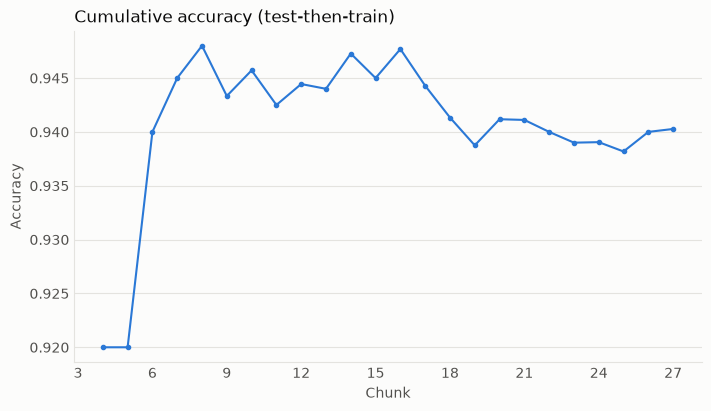

In [8]:
plot_metric_over_time(trainer.history("cumulative_accuracy"),
                      title="Cumulative accuracy (test-then-train)",
                      ylabel="Accuracy",
                      save_path="figures/cumulative_accuracy.png");

**Error and memory per chunk.** The `ax` option draws several plots in one figure.
The memory rises while the buffer fills and drops after each retrain, when the buffer
is cleared.

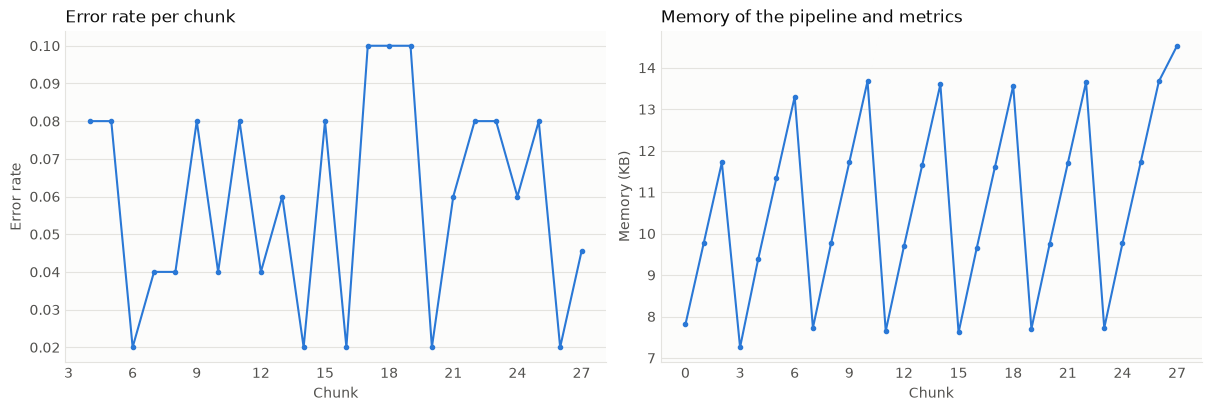

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
plot_metric_over_time(1 - trainer.history("accuracy"), title="Error rate per chunk",
                      ylabel="Error rate", ax=axes[0])
plot_metric_over_time(trainer.history("memory_bytes") / 1024,
                      title="Memory of the pipeline and metrics",
                      ylabel="Memory (KB)", ax=axes[1])
plt.show()

**Model comparison: effect of `buffer_size`.** The same stream is replayed with a
small and a large buffer. A small buffer gives a first tree sooner and retrains more
often, but each tree learns from fewer samples.

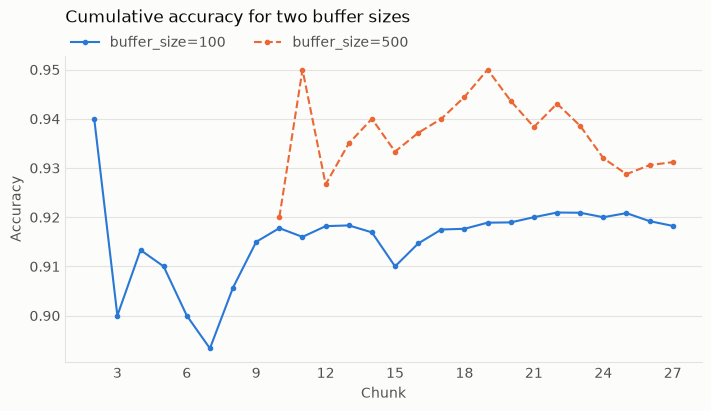

buffer_size=100: 13 retrains, accuracy 0.918, training time 15.0 ms
buffer_size=500: 2 retrains, accuracy 0.931, training time 6.5 ms


In [10]:
def run_stream(buffer_size):
    return StreamTrainer(make_pipeline(buffer_size)).run(chunks)


small, large = run_stream(100), run_stream(500)
compare_models(small.history("cumulative_accuracy"),
               large.history("cumulative_accuracy"),
               ("buffer_size=100", "buffer_size=500"),
               title="Cumulative accuracy for two buffer sizes",
               ylabel="Accuracy");

for name, run in (("buffer_size=100", small), ("buffer_size=500", large)):
    s = run.summary()
    print(f"{name}: {s['n_retrains']} retrains, accuracy {s['cumulative_accuracy']:.3f}, "
          f"training time {1000 * s['fit_time']:.1f} ms")

**Predictions against the ground truth.** The last chunk, predicted before the model
trained on it. Each dot is a note on the row of its true class; a cross marks a wrong
prediction, on the row of the predicted class.

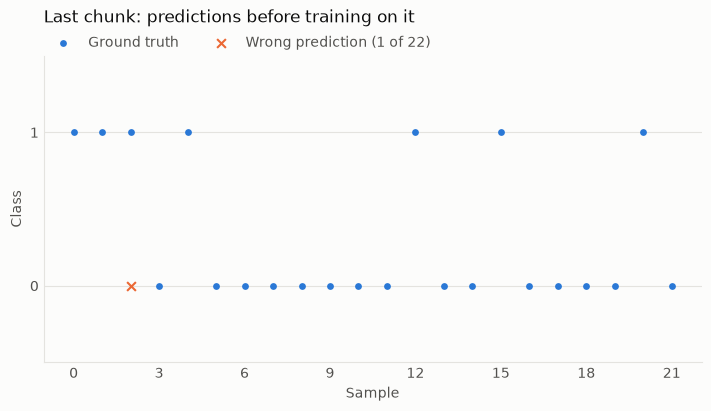

In [11]:
plot_predictions_vs_ground_truth(y_last, y_pred_last,
                                 title="Last chunk: predictions before training on it");

## 6. Streaming statistics

`StreamingStats` updates per-feature statistics one chunk at a time, without keeping
past chunks. Its mean and standard deviation are exact, so they match NumPy on the
whole dataset. The median is estimated from a random sample (a reservoir), which here
still holds every row, so it is exact too.

In [12]:
stats = StreamingStats(seed=SEED)
for X_chunk, _ in chunks:
    stats.update_stats(X_chunk)

print("Streaming mean:", np.round(stats.mean_, 4))
print("NumPy mean:    ", np.round(X.mean(axis=0), 4))
print("Same standard deviation:", np.allclose(stats.std_, X.std(axis=0)))
print("Same median:            ", np.allclose(stats.quantiles(0.5), np.median(X, axis=0)))

Streaming mean: [ 0.4337  1.9224  1.3976 -1.1917]
NumPy mean:     [ 0.4337  1.9224  1.3976 -1.1917]
Same standard deviation: True
Same median:             True


## 7. Missing values

The banknote data has no missing value, so `demo/data.csv` shows how `load_csv` reads
empty cells as `NaN`. A `SimpleImputer` then learns the column means from two chunks
with `partial_fit` and fills the gaps.

In [13]:
raw = load_csv("data.csv", skiprows=1)
print("Loaded:\n", raw)

imputer = SimpleImputer(strategy="mean")
for part in (raw[:2], raw[2:]):
    imputer.partial_fit(part)
print("Imputed:\n", imputer.transform(raw))

Loaded:
 [[ 1. nan  2.]
 [ 3.  4. nan]
 [ 5.  6.  7.]
 [ 8.  9. 10.]]
Imputed:
 [[ 1.          6.33333333  2.        ]
 [ 3.          4.          6.33333333]
 [ 5.          6.          7.        ]
 [ 8.          9.         10.        ]]


## 8. Conclusion

- The pipeline learned the stream incrementally: after its first retrain, its
  test-then-train accuracy stays high, well above the 55% obtained by always predicting
  the majority class.
- The buffer sets the trade-off of the streaming tree: a small buffer gives a model
  earlier and adapts more often; a large buffer trains each tree on more data, with
  fewer but longer retrains and more memory. `benchmark/bench_buffer_size.py` measures
  this trade-off on a longer stream with a concept drift.